# Predictive Modeling and Risk Scoring for Bank Customer Churn

**Goal:** predict which customers are likely to churn, produce a churn probability (0 to 1) and a risk band, and identify the key churn drivers.

| Item | Detail |
|---|---|
| Dataset | European Bank customer data (10,000 customers) |
| Target | `Exited` (1 = churned, 0 = retained) |
| Primary metrics | Recall, Precision, F1, ROC-AUC (not accuracy alone, because only about 20% of customers churn) |

**Notebook map**

1. Setup and data loading
2. Exploratory data analysis (EDA)
3. Preprocessing and feature engineering
4. Train/test split
5. Model training and cross-validation
6. Evaluation and threshold tuning
7. Explainability (feature importance, partial dependence, SHAP)
8. Risk scoring and what-if analysis
9. Save the model for the Streamlit app
10. Findings and recommendations

## 1. Setup and data loading

In [32]:
import warnings
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
DATA_PATH = r"C:\Users\NAINA\OneDrive\Documents\GitHub\Data_Analysis_Internship_Projects\Data_Analysis_Internship_Projects\Predictive Modeling and Risk Scoring for Bank Customer Churn\Data\European_Bank - European_Bank.csv"   # change if your file is elsewhere
OUT = Path("artifacts")
OUT.mkdir(exist_ok=True)

In [33]:
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate CustomerIds:", int(df["CustomerId"].duplicated().sum()))
print("Unique values in Year:", df["Year"].unique())
df.head()

Shape: (10000, 14)
Missing values: 0
Duplicate rows: 0
Duplicate CustomerIds: 0
Unique values in Year: [2025]


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [34]:
print(df.dtypes)
df.describe().T.round(2)

Year                 int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object


,count,mean,std,min,25%,50%,75%,max
Year,10000.0,2025.00,0.00,2025.00,2025.00,2025.00,2025.00,2025.00
CustomerId,10000.0,15690940.57,71936.19,15565701.00,15628528.25,15690738.00,15753233.75,15815690.00
CreditScore,10000.0,650.53,96.65,350.00,584.00,652.00,718.00,850.00
Age,10000.0,38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,10000.0,5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,10000.0,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
NumOfProducts,10000.0,1.53,0.58,1.00,1.00,1.00,2.00,4.00
HasCrCard,10000.0,0.71,0.46,0.00,0.00,1.00,1.00,1.00
IsActiveMember,10000.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
EstimatedSalary,10000.0,100090.24,57510.49,11.58,51002.11,100193.92,149388.25,199992.48


## 2. Exploratory data analysis

Questions to answer here: how imbalanced is the target, which segments churn most, and which variables look informative?

        customers  percent
Exited                    
0            7963    79.63
1            2037    20.37


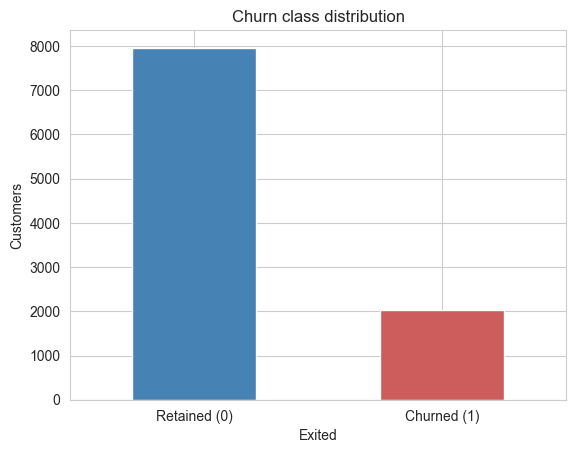

In [35]:
counts = df["Exited"].value_counts()
pct = df["Exited"].value_counts(normalize=True) * 100
print(pd.DataFrame({"customers": counts, "percent": pct.round(2)}))

ax = counts.plot(kind="bar", color=["steelblue", "indianred"])
ax.set_xticklabels(["Retained (0)", "Churned (1)"], rotation=0)
ax.set_title("Churn class distribution")
ax.set_ylabel("Customers")
plt.show()

### 2.1 Churn rate by segment

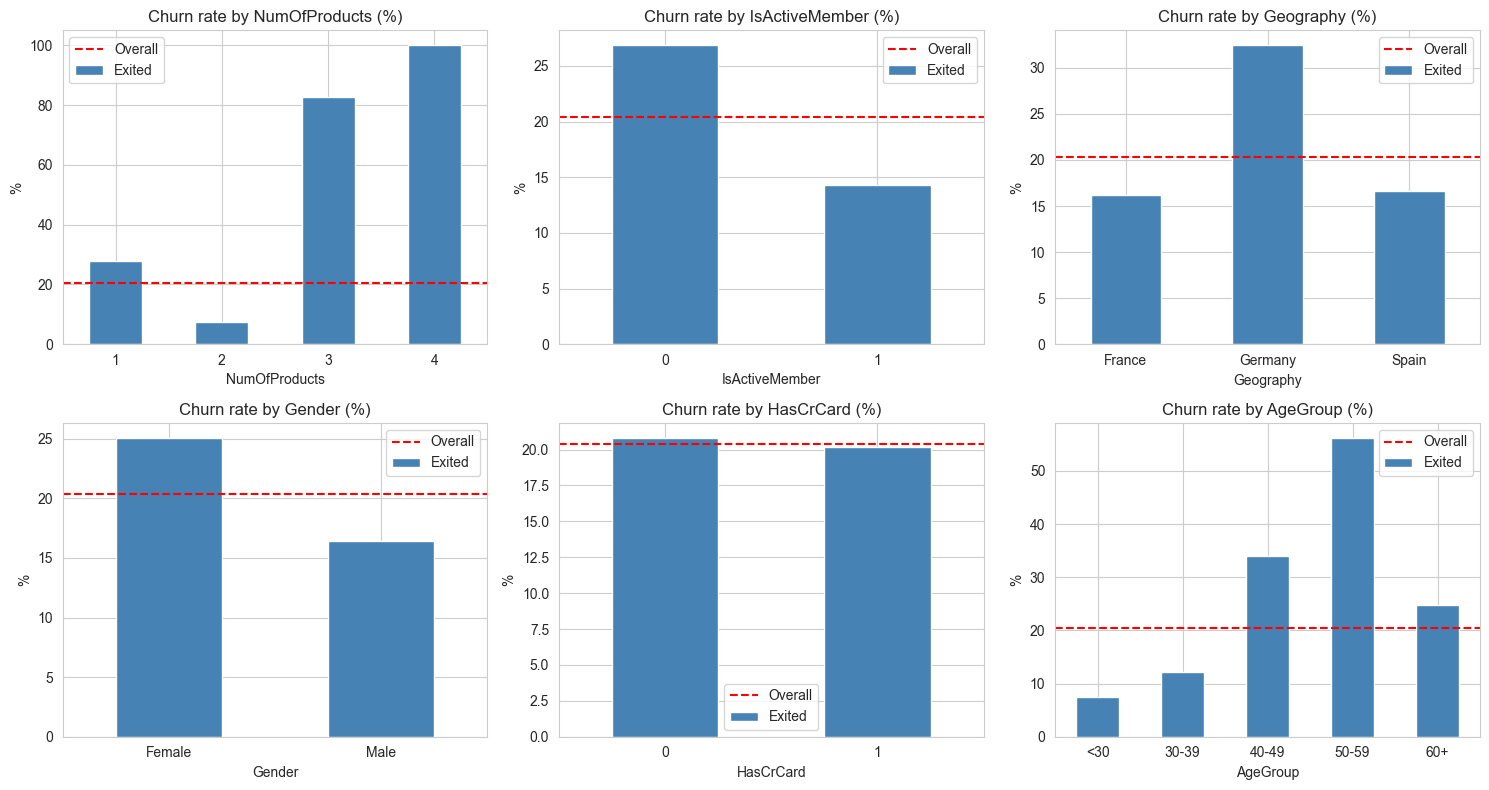

In [36]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 30, 40, 50, 60, 100],
                        labels=["<30", "30-39", "40-49", "50-59", "60+"])

segments = ["NumOfProducts", "IsActiveMember", "Geography", "Gender", "HasCrCard", "AgeGroup"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), segments):
    rate = df.groupby(col, observed=True)["Exited"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.axhline(df["Exited"].mean() * 100, color="red", linestyle="--", label="Overall")
    ax.set_title(f"Churn rate by {col} (%)")
    ax.set_ylabel("%")
    ax.tick_params(axis="x", rotation=0)
    ax.legend()
plt.tight_layout()
plt.show()

In [37]:
# Same information as numbers, with group sizes (small groups give unstable rates)
for col in segments:
    t = df.groupby(col, observed=True)["Exited"].agg(customers="count", churn_rate="mean")
    t["churn_rate"] = (t["churn_rate"] * 100).round(1)
    print(f"\n{col}\n{t}")


NumOfProducts
               customers  churn_rate
NumOfProducts                       
1                   5084        27.7
2                   4590         7.6
3                    266        82.7
4                     60       100.0

IsActiveMember
                customers  churn_rate
IsActiveMember                       
0                    4849        26.9
1                    5151        14.3

Geography
           customers  churn_rate
Geography                       
France          5014        16.2
Germany         2509        32.4
Spain           2477        16.7

Gender
        customers  churn_rate
Gender                       
Female       4543        25.1
Male         5457        16.5

HasCrCard
           customers  churn_rate
HasCrCard                       
0               2945        20.8
1               7055        20.2

AgeGroup
          customers  churn_rate
AgeGroup                       
<30            1968         7.5
30-39          4451        12.1
40-49     

### 2.2 Distributions, outliers and correlations

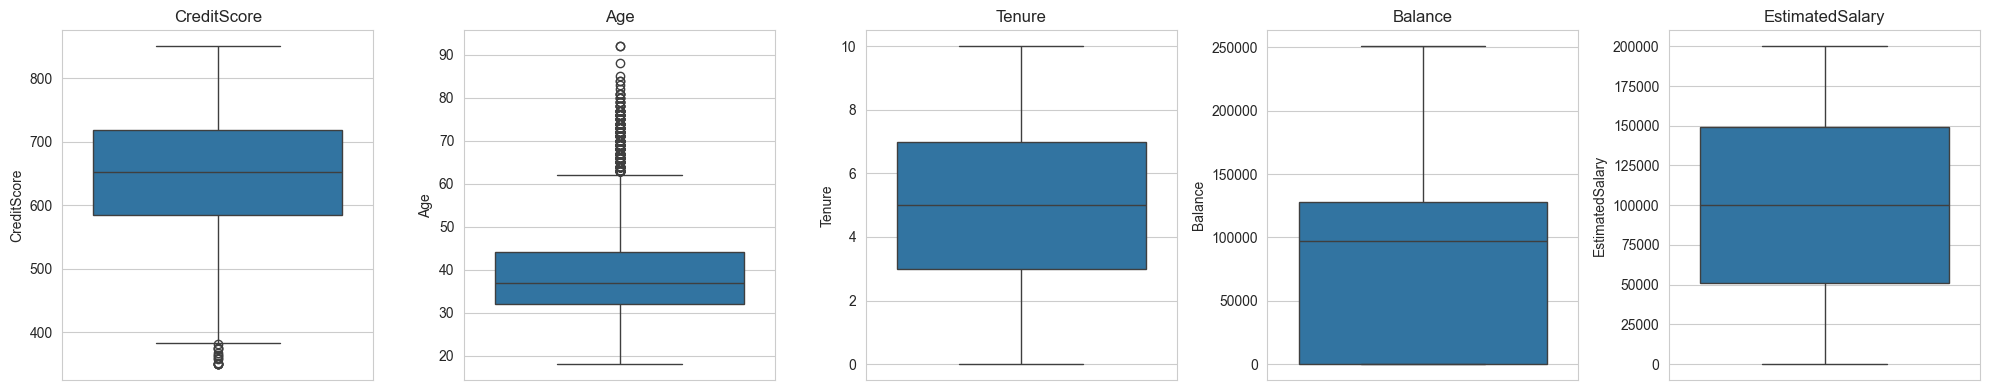

CreditScore: 15 IQR outliers
Age: 359 IQR outliers
Tenure: 0 IQR outliers
Balance: 0 IQR outliers
EstimatedSalary: 0 IQR outliers


In [38]:
num_cols_eda = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, num_cols_eda):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in num_cols_eda:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n_out} IQR outliers")

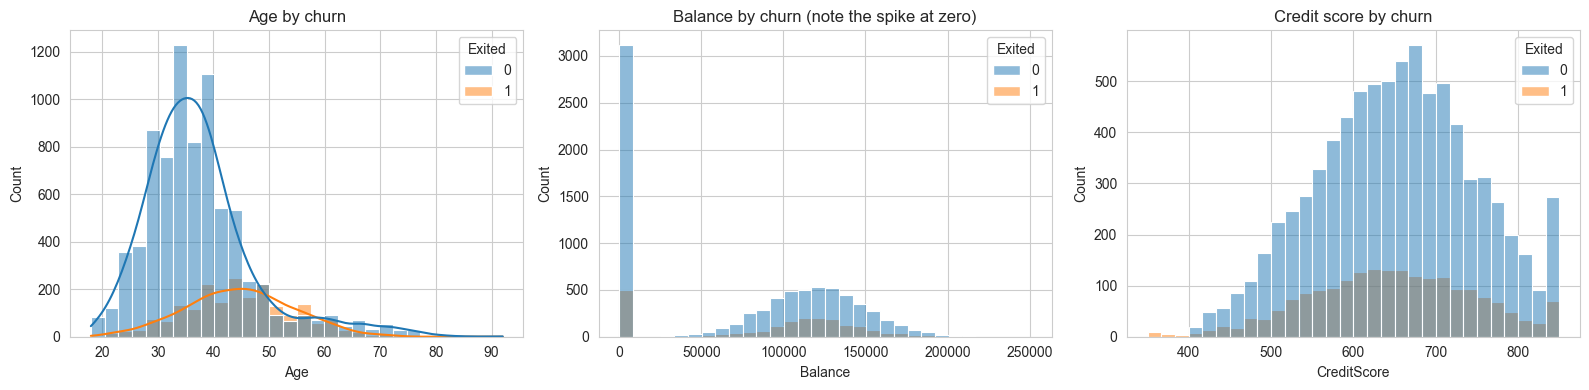

Share of customers with zero balance: 0.362
Balance
Has balance     0.241
Zero balance    0.138
Name: Exited, dtype: float64


In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=df, x="Age", hue="Exited", bins=30, kde=True, ax=axes[0])
sns.histplot(data=df, x="Balance", hue="Exited", bins=30, ax=axes[1])
sns.histplot(data=df, x="CreditScore", hue="Exited", bins=30, ax=axes[2])
axes[0].set_title("Age by churn")
axes[1].set_title("Balance by churn (note the spike at zero)")
axes[2].set_title("Credit score by churn")
plt.tight_layout()
plt.show()

print("Share of customers with zero balance:", round((df["Balance"] == 0).mean(), 3))
print(df.groupby(df["Balance"] == 0)["Exited"].mean().rename({True: "Zero balance", False: "Has balance"}).round(3))

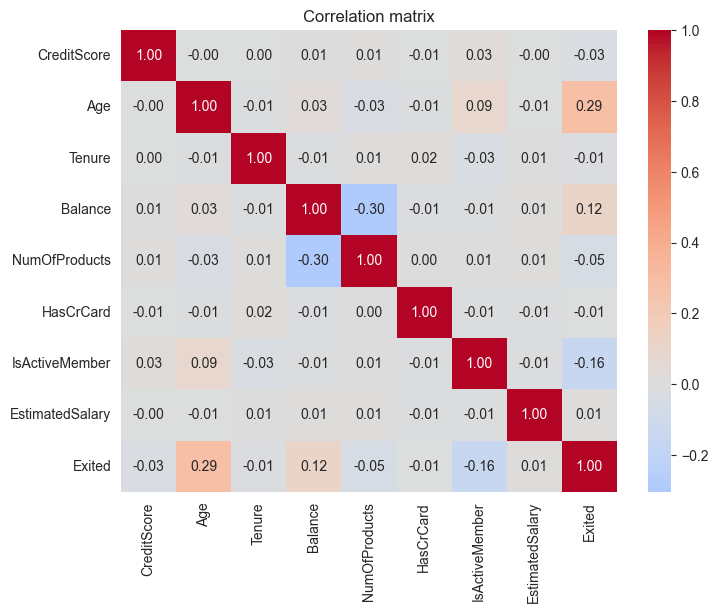

Age                0.285
IsActiveMember    -0.156
Balance            0.119
NumOfProducts     -0.048
CreditScore       -0.027
Tenure            -0.014
EstimatedSalary    0.012
HasCrCard         -0.007
Name: Exited, dtype: float64

In [40]:
plt.figure(figsize=(8, 6))
corr = df.drop(columns=["CustomerId", "Year"]).corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()
corr["Exited"].drop("Exited").sort_values(key=abs, ascending=False).round(3)

**Things to note (write your own interpretation in Section 10):**

- `NumOfProducts` is clearly non-linear: compare the churn rate for 1, 2, 3 and 4 products, and note how few customers hold 3 or 4.
- Pearson correlation understates variables such as `NumOfProducts` and `Age`, because their relationship with churn is not a straight line.
- Check whether the demographic variables (Age, Geography, Gender) matter as much as the engagement variables (`IsActiveMember`, `NumOfProducts`).

## 3. Preprocessing and feature engineering

**Preprocessing**

- Drop `Year` (constant), `CustomerId` and `Surname` (identifiers, no predictive value)
- One-hot encode `Geography` and `Gender` (drop first level)
- Scale numeric features (needed for Logistic Regression, harmless for trees)

**Feature engineering** (row-level maths only, so it is safe to do before the split)

| Feature | Meaning |
|---|---|
| `BalanceSalaryRatio` | Balance relative to salary |
| `ProductDensity` | Products held per year of tenure |
| `ActiveXProducts` | Engagement-product interaction |
| `AgeXTenure` | Age-tenure interaction |
| `ZeroBalance` | Flag for an empty account |

In [41]:
TARGET = "Exited"
DROP_COLS = ["Year", "CustomerId", "Surname"]
CAT_COLS = ["Geography", "Gender"]
NUM_COLS = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary",
            "BalanceSalaryRatio", "ProductDensity", "AgeXTenure"]
RAW_FEATURES = ["CreditScore", "Geography", "Gender", "Age", "Tenure", "Balance",
                "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"]


def add_features(data):
    out = data.copy()
    out["BalanceSalaryRatio"] = out["Balance"] / (out["EstimatedSalary"] + 1)
    out["ProductDensity"] = out["NumOfProducts"] / (out["Tenure"] + 1)
    out["ActiveXProducts"] = out["IsActiveMember"] * out["NumOfProducts"]
    out["AgeXTenure"] = out["Age"] * out["Tenure"]
    out["ZeroBalance"] = (out["Balance"] == 0).astype(int)
    return out


y = df[TARGET]
X = add_features(df.drop(columns=DROP_COLS + [TARGET, "AgeGroup"]))
print("Feature matrix:", X.shape)
X.head()

Feature matrix: (10000, 15)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,BalanceSalaryRatio,ProductDensity,ActiveXProducts,AgeXTenure,ZeroBalance
0,619,France,Female,42,2,0.00,1,1,1,101348.88,0.000000,0.333333,1,84,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0.744670,0.500000,1,41,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1.401362,0.333333,0,336,0
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0.000000,1.000000,0,39,1
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,1.587035,0.333333,1,86,0


In [42]:
# Do the new features carry signal? Quick check against the target.
new_feats = ["BalanceSalaryRatio", "ProductDensity", "ActiveXProducts", "AgeXTenure", "ZeroBalance"]
check = X[new_feats].copy()
check["Exited"] = y
print(check.corr()["Exited"].drop("Exited").round(3))

BalanceSalaryRatio    0.026
ProductDensity       -0.006
ActiveXProducts      -0.138
AgeXTenure            0.102
ZeroBalance          -0.122
Name: Exited, dtype: float64


## 4. Train/test split

Stratified 80/20 split keeps the churn rate the same in both sets. The test set is used **once**, for final reporting only. Model selection uses cross-validation on the training set.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

Train: (8000, 15) | Test: (2000, 15)
Churn rate train: 0.2037 | test: 0.2035


In [44]:
def build_preprocessor():
    pre = ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), CAT_COLS),
            ("num", StandardScaler(), NUM_COLS),
        ],
        remainder="passthrough",          # binary and product columns pass through
        verbose_feature_names_out=False,
    )
    pre.set_output(transform="pandas")
    return pre


# Sanity checks: fit on train only, transform test
check_pre = build_preprocessor()
Xt_train = check_pre.fit_transform(X_train)
Xt_test = check_pre.transform(X_test)
assert Xt_train.isna().sum().sum() == 0 and Xt_test.isna().sum().sum() == 0
print("Transformed shapes:", Xt_train.shape, Xt_test.shape)
print(list(Xt_train.columns))

Transformed shapes: (8000, 16) (2000, 16)
['Geography_Germany', 'Geography_Spain', 'Gender_Male', 'CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'AgeXTenure', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'ActiveXProducts', 'ZeroBalance']


## 5. Model training and cross-validation

Models, in order of complexity: Logistic Regression (interpretable baseline), Decision Tree, Random Forest, Gradient Boosting, XGBoost (optional).
Imbalance is handled with class weights. Each model sits inside a Pipeline with the preprocessor, so scaling and encoding are fitted inside each CV fold (no leakage).

In [45]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

def get_models():
    models = {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced",
                                                  random_state=RANDOM_STATE),
        "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=30,
                                                class_weight="balanced", random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                                class_weight="balanced", n_jobs=-1,
                                                random_state=RANDOM_STATE),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                                        max_depth=3, subsample=0.8,
                                                        random_state=RANDOM_STATE),
    }
    if HAS_XGB:
        models["XGBoost"] = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                          subsample=0.8, colsample_bytree=0.8,
                                          scale_pos_weight=scale_pos_weight,
                                          eval_metric="logloss", n_jobs=-1,
                                          random_state=RANDOM_STATE)
    return models


def make_pipeline(model):
    return Pipeline([("prep", build_preprocessor()), ("model", model)])


def metrics_at(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "ROC_AUC": roc_auc_score(y_true, proba)}


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "precision": "precision"}

rows, fitted = [], {}
for name, model in get_models().items():
    pipe = make_pipeline(model)
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    test_m = metrics_at(y_test, pipe.predict_proba(X_test)[:, 1], 0.5)
    rows.append({"Model": name,
                 "CV_ROC_AUC": res["test_roc_auc"].mean(),
                 "CV_ROC_AUC_std": res["test_roc_auc"].std(),
                 "CV_F1": res["test_f1"].mean(),
                 **{f"Test_{k}": v for k, v in test_m.items()}})

comparison = pd.DataFrame(rows).sort_values("CV_ROC_AUC", ascending=False).reset_index(drop=True)
comparison.round(4)

,Model,CV_ROC_AUC,CV_ROC_AUC_std,CV_F1,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
0,Gradient Boosting,0.8637,0.0087,0.5824,0.8685,0.7903,0.4816,0.5985,0.8719
1,XGBoost,0.8611,0.0106,0.6063,0.8060,0.5166,0.7273,0.6041,0.8641
2,Random Forest,0.8577,0.0115,0.6027,0.8140,0.5313,0.7297,0.6149,0.8674
3,Decision Tree,0.8270,0.0125,0.5547,0.7700,0.4609,0.7666,0.5756,0.8381
4,Logistic Regression,0.7658,0.0211,0.4884,0.7125,0.3868,0.7052,0.4996,0.7759


**How to read this table:** models are ranked by cross-validated ROC-AUC (a fair selection criterion that does not touch the test set). Test metrics at the default 0.5 threshold are shown for reporting. Notice how recall and precision trade off between models, and how far the simple baseline is from the tree-based models.

## 6. Evaluation and threshold tuning

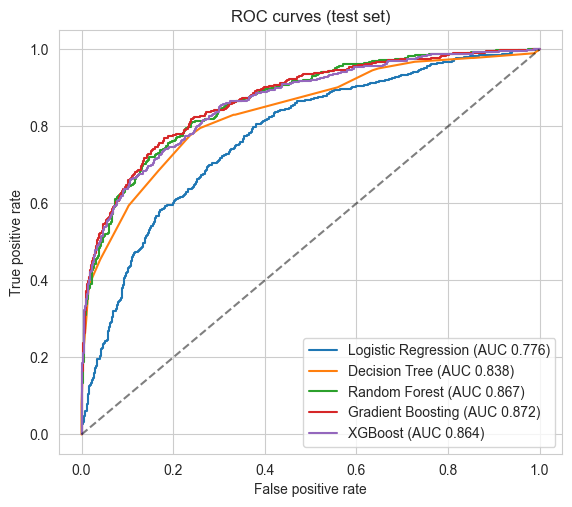

In [46]:
plt.figure(figsize=(6.5, 5.5))
for name, pipe in fitted.items():
    p = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves (test set)")
plt.legend(loc="lower right")
plt.show()

Best model by cross-validated ROC-AUC: Gradient Boosting
Tuned threshold (max F1, out-of-fold): 0.30


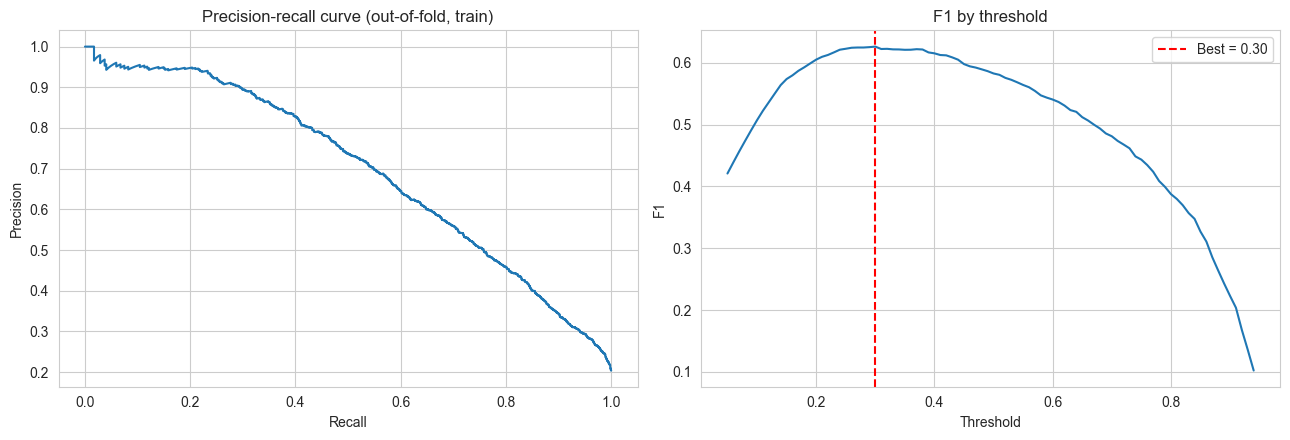

In [47]:
best_name = comparison.loc[0, "Model"]
best = fitted[best_name]
print("Best model by cross-validated ROC-AUC:", best_name)

# Threshold chosen on OUT-OF-FOLD training predictions, never on the test set
oof = cross_val_predict(make_pipeline(get_models()[best_name]), X_train, y_train,
                        cv=cv, method="predict_proba")[:, 1]

grid = np.arange(0.05, 0.95, 0.01)
f1_by_t = [f1_score(y_train, (oof >= t).astype(int)) for t in grid]
threshold = float(grid[int(np.argmax(f1_by_t))])
print(f"Tuned threshold (max F1, out-of-fold): {threshold:.2f}")

prec, rec, thr = precision_recall_curve(y_train, oof)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(rec, prec)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-recall curve (out-of-fold, train)")
axes[1].plot(grid, f1_by_t)
axes[1].axvline(threshold, color="red", linestyle="--", label=f"Best = {threshold:.2f}")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("F1")
axes[1].set_title("F1 by threshold")
axes[1].legend()
plt.tight_layout()
plt.show()

In [48]:
proba_test = best.predict_proba(X_test)[:, 1]

# Precision/recall trade-off at several thresholds (test set, for reporting)
table = pd.DataFrame({t: metrics_at(y_test, proba_test, t)
                      for t in [0.20, 0.30, round(threshold, 2), 0.40, 0.50, 0.60]}).T
table.index.name = "threshold"
table.round(3)

,Accuracy,Precision,Recall,F1,ROC_AUC
threshold,,,,,
0.2,0.804,0.511,0.769,0.614,0.872
0.3,0.850,0.623,0.658,0.640,0.872
0.4,0.863,0.703,0.565,0.627,0.872
0.5,0.868,0.790,0.482,0.598,0.872
0.6,0.865,0.874,0.393,0.542,0.872


              precision    recall  f1-score   support

    Retained       0.91      0.90      0.90      1593
     Churned       0.62      0.66      0.64       407

    accuracy                           0.85      2000
   macro avg       0.77      0.78      0.77      2000
weighted avg       0.85      0.85      0.85      2000



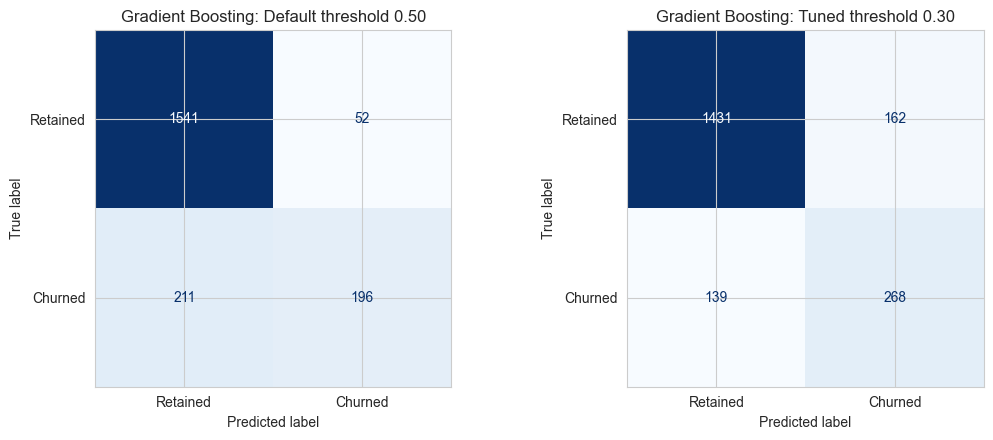

In [49]:
pred_tuned = (proba_test >= threshold).astype(int)
print(classification_report(y_test, pred_tuned, target_names=["Retained", "Churned"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (t, title) in zip(axes, [(0.5, "Default threshold 0.50"), (threshold, f"Tuned threshold {threshold:.2f}")]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (proba_test >= t).astype(int)),
                           display_labels=["Retained", "Churned"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{best_name}: {title}")
plt.tight_layout()
plt.show()

**Business reading of the threshold (Indian FinTech angle):** a false positive is a retention offer or call sent to a customer who was not leaving (wasted cost, like an unnecessary cashback). A false negative is a lost customer. The right threshold depends on which error costs more, so state your reasoning in the paper.

## 7. Explainability

Three views: permutation importance (model-agnostic), partial dependence (shape of the effect) and SHAP (direction and per-customer explanation).

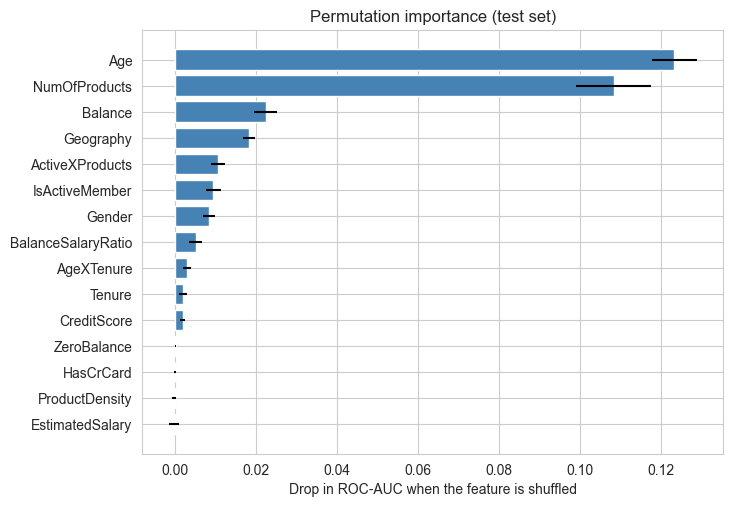

,feature,importance_mean,importance_std
0,Age,0.1233,0.0056
1,NumOfProducts,0.1083,0.0092
2,Balance,0.0223,0.0028
3,Geography,0.0182,0.0015
4,ActiveXProducts,0.0106,0.0018
5,IsActiveMember,0.0095,0.0019
6,Gender,0.0084,0.0016
7,BalanceSalaryRatio,0.0051,0.0016
8,AgeXTenure,0.0030,0.0010
9,Tenure,0.0019,0.0011


In [50]:
imp = permutation_importance(best, X_test, y_test, scoring="roc_auc",
                             n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
imp_df = (pd.DataFrame({"feature": X_test.columns,
                        "importance_mean": imp.importances_mean,
                        "importance_std": imp.importances_std})
          .sort_values("importance_mean", ascending=False).reset_index(drop=True))

top = imp_df.head(15).iloc[::-1]
plt.figure(figsize=(7.5, 5.5))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color="steelblue")
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.title("Permutation importance (test set)")
plt.show()
imp_df.round(4)

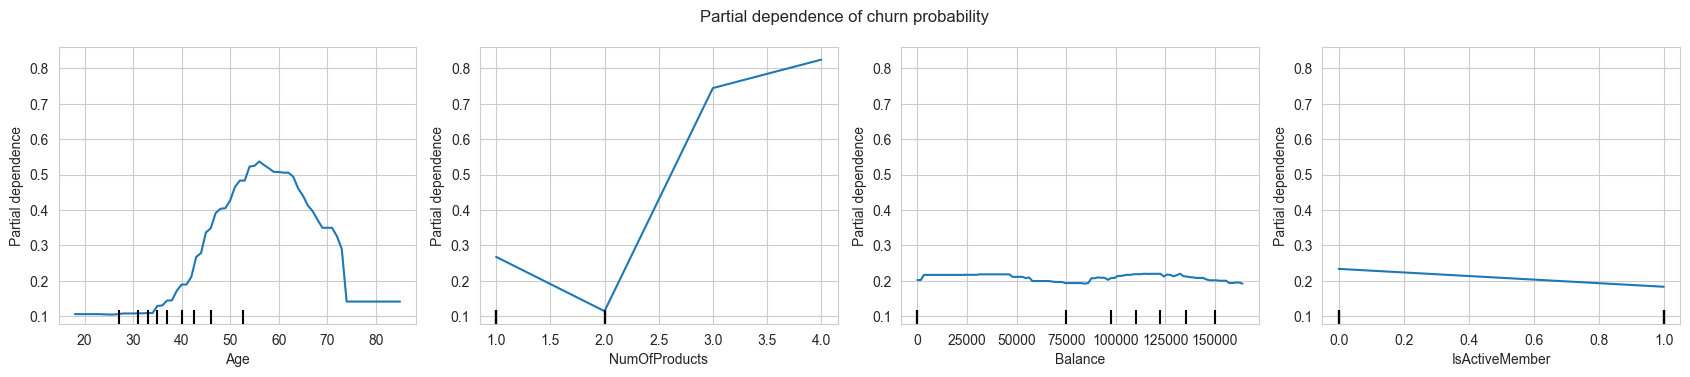

In [51]:
# Partial dependence (integer columns must be float for sklearn)
X_pdp = X_test.copy()
int_cols = X_pdp.select_dtypes(include="integer").columns
X_pdp[int_cols] = X_pdp[int_cols].astype(float)

features = ["Age", "NumOfProducts", "Balance", "IsActiveMember"]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
PartialDependenceDisplay.from_estimator(best, X_pdp, features, ax=ax, kind="average")
fig.suptitle("Partial dependence of churn probability")
plt.tight_layout()
plt.show()

In [52]:
# SHAP (tree-based best model). Skipped automatically if shap is not installed.
try:
    import shap
    model = best.named_steps["model"]
    Xt = best.named_steps["prep"].transform(X_test)
    sv = shap.TreeExplainer(model).shap_values(Xt)
    if isinstance(sv, list):
        sv = sv[1]
    elif getattr(sv, "ndim", 2) == 3:
        sv = sv[:, :, 1]
    shap.summary_plot(sv, Xt)
except Exception as exc:
    print("SHAP skipped:", exc)

SHAP skipped: No module named 'shap'


## 8. Risk scoring and what-if analysis

Each customer gets a churn probability, a binary flag at the tuned threshold and a risk band. The 0.30 and 0.60 band cut-offs are a starting point. Adjust them to the retention budget and justify your choice.

          customers  actual_churn_rate
RiskBand                              
Low            1570                8.9
Medium          247               43.7
High            183               87.4


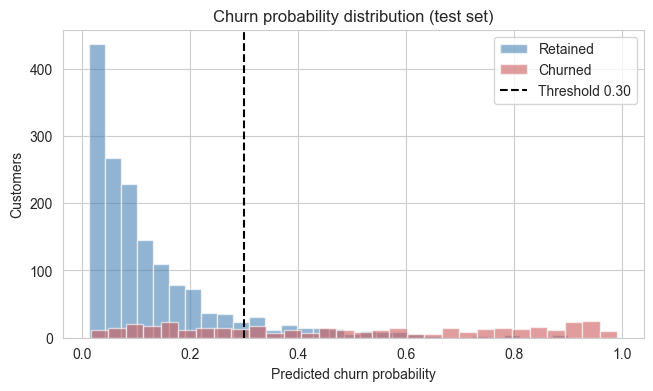

In [53]:
RISK_BANDS = (0.30, 0.60)

def risk_label(p, bands=RISK_BANDS):
    return "Low" if p < bands[0] else ("Medium" if p < bands[1] else "High")


def score_customers(pipeline, raw_df, threshold, bands=RISK_BANDS):
    feats = add_features(raw_df[RAW_FEATURES])
    p = pipeline.predict_proba(feats)[:, 1]
    return pd.DataFrame({"ChurnProbability": p,
                         "ChurnFlag": (p >= threshold).astype(int),
                         "RiskBand": [risk_label(v, bands) for v in p]}, index=raw_df.index)


scored = score_customers(best, df.loc[X_test.index], threshold)
scored["Exited"] = y_test
summary = (scored.groupby("RiskBand")
           .agg(customers=("Exited", "size"), actual_churn_rate=("Exited", "mean"))
           .reindex(["Low", "Medium", "High"]))
summary["actual_churn_rate"] = (summary["actual_churn_rate"] * 100).round(1)
print(summary)

plt.figure(figsize=(7.5, 4))
plt.hist(scored.loc[scored.Exited == 0, "ChurnProbability"], bins=30, alpha=0.6, label="Retained", color="steelblue")
plt.hist(scored.loc[scored.Exited == 1, "ChurnProbability"], bins=30, alpha=0.6, label="Churned", color="indianred")
plt.axvline(threshold, color="black", linestyle="--", label=f"Threshold {threshold:.2f}")
plt.xlabel("Predicted churn probability")
plt.ylabel("Customers")
plt.title("Churn probability distribution (test set)")
plt.legend()
plt.show()

**A well-behaved risk score** should show actual churn rising steadily from Low to High in the table above. If it does not, revisit the band cut-offs or check calibration.

### What-if scenario simulator

Change one input for a sample customer and watch the probability move. This is the logic behind the Streamlit simulator.

In [54]:
base = pd.DataFrame([{"CreditScore": 600, "Geography": "Germany", "Gender": "Female", "Age": 45,
                      "Tenure": 4, "Balance": 110000.0, "NumOfProducts": 1, "HasCrCard": 1,
                      "IsActiveMember": 0, "EstimatedSalary": 80000.0}])

rows = []
for prods in [1, 2, 3, 4]:
    for active in [0, 1]:
        c = base.copy()
        c["NumOfProducts"] = prods
        c["IsActiveMember"] = active
        r = score_customers(best, c, threshold).iloc[0]
        rows.append({"NumOfProducts": prods, "IsActiveMember": active,
                     "ChurnProbability": round(r.ChurnProbability, 3), "RiskBand": r.RiskBand})

whatif = pd.DataFrame(rows).pivot(index="NumOfProducts", columns="IsActiveMember", values="ChurnProbability")
whatif.columns = ["Inactive", "Active"]
whatif

,Inactive,Active
NumOfProducts,,
1,0.766,0.559
2,0.452,0.299
3,0.920,0.945
4,0.947,0.966


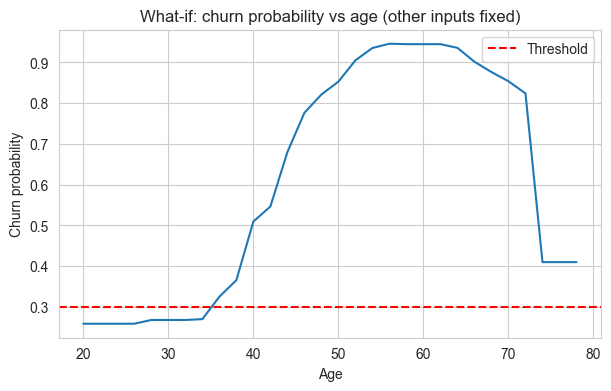

In [55]:
# One-variable sweep: how does risk change with age for this customer?
ages = np.arange(20, 80, 2)
sweep = pd.concat([base.assign(Age=a) for a in ages], ignore_index=True)
sweep_p = score_customers(best, sweep, threshold)["ChurnProbability"]

plt.figure(figsize=(7, 4))
plt.plot(ages, sweep_p)
plt.axhline(threshold, color="red", linestyle="--", label="Threshold")
plt.xlabel("Age")
plt.ylabel("Churn probability")
plt.title("What-if: churn probability vs age (other inputs fixed)")
plt.legend()
plt.show()

## 9. Save the model for the Streamlit app

Save the whole Pipeline (preprocessing + model), the threshold and the metadata the app needs.

In [56]:
joblib.dump(best, OUT / "churn_pipeline.joblib")
comparison.to_csv(OUT / "model_comparison.csv", index=False)
imp_df.to_csv(OUT / "feature_importance.csv", index=False)
pd.DataFrame({"ChurnProbability": proba_test, "Exited": y_test.values}).to_csv(OUT / "test_scores.csv", index=False)

meta = {
    "best_model": best_name,
    "threshold": threshold,
    "risk_bands": list(RISK_BANDS),
    "raw_features": RAW_FEATURES,
    "test_metrics_default_0.5": metrics_at(y_test, proba_test, 0.5),
    "test_metrics_tuned": metrics_at(y_test, proba_test, threshold),
    "feature_ranges": {c: [float(X[c].min()), float(X[c].max())]
                       for c in ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary", "NumOfProducts"]},
    "geographies": sorted(df["Geography"].unique().tolist()),
    "genders": sorted(df["Gender"].unique().tolist()),
}
(OUT / "metadata.json").write_text(json.dumps(meta, indent=2))
print("Saved to", OUT.resolve())
print(sorted(p.name for p in OUT.iterdir()))

Saved to C:\Users\NAINA\OneDrive\Documents\GitHub\Data_Analysis_Internship_Projects\Data_Analysis_Internship_Projects\Predictive Modeling and Risk Scoring for Bank Customer Churn\Notebook\artifacts
['churn_pipeline.joblib', 'feature_importance.csv', 'metadata.json', 'model_comparison.csv', 'test_scores.csv']


## 10. Findings and recommendations

*Write this section in your own words after reading your results. A suggested structure:*

**Key findings**

1. Model performance: which model won, and by how much over the Logistic Regression baseline?
2. Top churn drivers from permutation importance and SHAP. Do engagement variables rank above demographics?
3. Segment insights: which groups (product count, age band, geography, activity) carry the highest churn risk?

**Recommendations (segment-based retention)**

| Segment | Observed risk | Suggested action | Expected benefit |
|---|---|---|---|
| (fill in) | | | |
| (fill in) | | | |
| (fill in) | | | |

**Limitations**

- Single snapshot of customers, no time dimension
- Some segments are small (for example customers with 3 or 4 products), so their rates are unstable
- Demographic variables (Gender, Geography) carry fairness considerations when used for targeting
- Risk bands and threshold depend on retention cost assumptions

**Future work:** cost-sensitive thresholding, probability calibration, monitoring for drift after deployment.